# 実験3 (ex003): 5次元多峰性 Levy 関数近似問題におけるNAQの性能検証 (論文 Table III の再現)

本ノートブックでは，Ninomiya (NOLTA, IEICE 2017) の **4.1節 Example 2** に基づき，多数の局所解を持つ高非線形・多峰性の **5次元 Levy 関数** に対する大規模ニューラルネットワーク（隠れ層150ニューロン，パラメータ次元 $\dim(\mathbf{w}) = 1,051$）の学習実験を行い，提案手法 **NAQ** の有効性とスケーラビリティを検証する．

## 実験条件（論文準拠）
- **対象関数**: 5次元 Levy 関数 $f_2(x_1, \dots, x_5), \; x_i \in [-4, 4]$
- **データセット**:
  - $[-4, 4]^5$ の一様乱数により $15,000$ 点を生成し，訓練データ $T_r$ に $10,000$ 点，テストデータ $T_e$ に $5,000$ 点を使用
  - 入出力の各要素を $[-1.0, 1.0]$ に正規化
- **ネットワーク構造**: 5入力 – 隠れ層150ニューロン（シグモイド関数） – 1線形出力（パラメータ総数 $\dim(\mathbf{w}) = 5 \times 150 + 150 + 150 \times 1 + 1 = 1,051$，逆ヘッセ近似行列 $\hat{\mathbf{H}}_k \in \mathbb{R}^{1051 \times 1051}$）
- **重み初期化と独立試行回数**: $[-0.5, 0.5]$ の一様乱数により初期化し，**10回** の独立試行を実施
- **終了条件**: $\|\nabla E(\mathbf{w}_k)\| \le \epsilon \; (\epsilon = 1 \times 10^{-8})$ または最大反復回数 $k_{\max} = 100,000$

In [1]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model import FeedforwardMLP5D, BatchedMLP5D
from utils import (
    setup_japanese_matplotlib,
    load_or_create_ex2_dataset,
    generate_initial_weights_ex2,
    run_first_order_group_ex2,
    run_second_order_ex2,
    format_ex2_dataframe,
)

setup_japanese_matplotlib()
os.makedirs("../report/img", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU'})")

# モデルパラメータ次元の確認
ref_model = FeedforwardMLP5D(n_in=5, n_hid=150, n_out=1)
print(f"ネットワーク構造: 5 - 150 - 1 | 総パラメータ次元 dim(w) = {ref_model.num_params}")

ds = load_or_create_ex2_dataset(dataset_dir="../datasets", seed=2, device=device)
print(f"訓練データ形状: X={tuple(ds['X_train_64'].shape)}, テストデータ形状: X={tuple(ds['X_test_64'].shape)}")

# 10試行分の共通初期重み ([-0.5, 0.5] 一様乱数)
w_init_10 = generate_initial_weights_ex2(num_runs=10, num_params=1051, seed=2017, device=device)

使用デバイス: cuda (NVIDIA GeForce RTX 4080)
ネットワーク構造: 5 - 150 - 1 | 総パラメータ次元 dim(w) = 1051
訓練データ形状: X=(10000, 5), テストデータ形状: X=(5000, 5)


## 1. 1次学習アルゴリズム（SG, NAG, Qprop）の実行

論文では Intel Core i7 3930K CPU 上で1試行あたり約 4,200〜7,970 秒（全条件合計で100時間超）を要した1次手法群を，TorchScript融合カーネルと全条件・全10試行の統合GPUバッチ並列化により数分で実行する．

In [2]:
# 1-A: 固定ステップ幅 (alpha_k = 0.01) の1次手法群 (5条件 × 10試行 = 50試行一括)
fixed_configs = [
    ("SG",  "fixed", 0.00),
    ("NAG", "fixed", 0.80),
    ("NAG", "fixed", 0.85),
    ("NAG", "fixed", 0.90),
    ("NAG", "fixed", 0.95),
]
res_fixed, curves_fixed = run_first_order_group_ex2(
    configs=fixed_configs,
    w_init_10_64=w_init_10,
    ds=ds,
    max_epochs=100000,
    eps=1e-8,
    fixed_lr=0.01,
    record_stride=1000,
)

# 1-B: Armijo直線探索を用いる1次手法群 (6条件 × 10試行 = 60試行一括)
armijo_1st_configs = [
    ("SG",    "Armijo", 0.00),
    ("NAG",   "Armijo", 0.80),
    ("NAG",   "Armijo", 0.85),
    ("NAG",   "Armijo", 0.90),
    ("NAG",   "Armijo", 0.95),
    ("Qprop", "Armijo", 0.00),
]
res_armijo_1st, curves_armijo_1st = run_first_order_group_ex2(
    configs=armijo_1st_configs,
    w_init_10_64=w_init_10,
    ds=ds,
    max_epochs=100000,
    eps=1e-8,
    max_step_norm=2.0,
    record_stride=1000,
)

Ex2 1st-Order (Armijo, 6x10=60 runs): 100%|##########| 100000/100000 [1:18:17<00:00, 21.29it/s]


## 2. 2次学習アルゴリズム（QN および 提案手法 NAQ）の実行

$\dim(\mathbf{w}) = 1,051$ の逆ヘッセ近似行列 $\hat{\mathbf{H}}_k \in \mathbb{R}^{1051 \times 1051}$ を IEEE 754 倍精度浮動小数点 (`float64`) で厳密に更新し，$\epsilon = 1 \times 10^{-8}$ の高精度終了条件のもとで QN と NAQ ($\mu = 0.80, 0.85, 0.90, 0.95$) を比較する．

In [3]:
res_2nd = []
curves_2nd = {}

# QN (Armijo)
r_qn, ep_qn, c_qn = run_second_order_ex2(
    algo="QN", mu=0.0, w_init_10_64=w_init_10, ds=ds,
    max_epochs=100000, eps=1e-8, max_step_norm=2.0, record_stride=250
)
res_2nd.append(r_qn)
curves_2nd["QN"] = (ep_qn, c_qn)

# NAQ (Armijo, mu = 0.80, 0.85, 0.90, 0.95)
for mu_val in [0.80, 0.85, 0.90, 0.95]:
    r_naq, ep_naq, c_naq = run_second_order_ex2(
        algo="NAQ", mu=mu_val, w_init_10_64=w_init_10, ds=ds,
        max_epochs=100000, eps=1e-8, max_step_norm=2.0, record_stride=250
    )
    res_2nd.append(r_naq)
    curves_2nd[f"NAQ({mu_val:.2f})"] = (ep_naq, c_naq)

# Table III の順序に結合して集計
# SG(fixed), SG(Armijo), NAG(fixed x4), NAG(Armijo x4), Qprop(Armijo), QN(Armijo), NAQ(Armijo x4)
ordered_results = (
    [res_fixed[0], res_armijo_1st[0]]
    + res_fixed[1:]
    + res_armijo_1st[1:5]
    + [res_armijo_1st[5]]
    + res_2nd
)

df_table3 = format_ex2_dataframe(ordered_results)
df_table3.to_csv("../datasets/ex003_table3_results.csv", index=False, encoding="utf-8-sig")
df_table3

NAQ (Armijo, mu=0.95): 100%|##########| 100000/100000 [27:53<00:00, 59.74it/s, E_ave=0.00010, active=10, gnorm=3.65e-08]


,Algorithm,Stepsize,mu,E_train (x10^3) Ave/Best/Worst,Ave. T(sec)/run,Batch GPU T(sec),Ave. epochs,E_test (x10^3) Ave/Best/Worst
0,SG,fixed,-,35.57930 / 34.11920 / 38.26581,26.53,1326.4,100000,35.96661 / 34.56646 / 38.75411
1,SG,Armijo,-,22.49564 / 21.43999 / 23.79734,78.29,4697.6,100000,23.42035 / 22.32526 / 24.68323
2,NAG,fixed,0.80,24.55254 / 23.71334 / 25.85327,26.53,1326.4,100000,25.48135 / 24.64458 / 26.68892
3,NAG,fixed,0.85,22.91146 / 21.93697 / 24.11433,26.53,1326.4,100000,23.84252 / 22.83928 / 25.00414
4,NAG,fixed,0.90,19.52786 / 17.48925 / 21.44864,26.53,1326.4,100000,20.36593 / 18.16590 / 22.32665
5,NAG,fixed,0.95,15.53744 / 14.91017 / 16.01765,26.53,1326.4,100000,16.11115 / 15.46653 / 16.57097
6,NAG,Armijo,0.80,15.18669 / 11.83775 / 16.24443,78.29,4697.6,100000,15.74751 / 12.32760 / 16.78448
7,NAG,Armijo,0.85,12.83903 / 8.67978 / 15.35074,78.29,4697.6,100000,13.45647 / 9.51033 / 15.96898
8,NAG,Armijo,0.90,9.64404 / 4.73803 / 13.77569,78.29,4697.6,100000,10.25218 / 4.97237 / 14.29629
9,NAG,Armijo,0.95,5.53255 / 1.80379 / 13.21544,78.29,4697.6,100000,5.94681 / 1.89716 / 13.55696


## 3. 収束曲線および手法別性能指標の可視化

5次元 Levy 関数における1次手法と2次手法（QN, NAQ）の収束挙動の決定的な差異，および NAQ による QN からの反復回数・計算時間の短縮効果を可視化する．

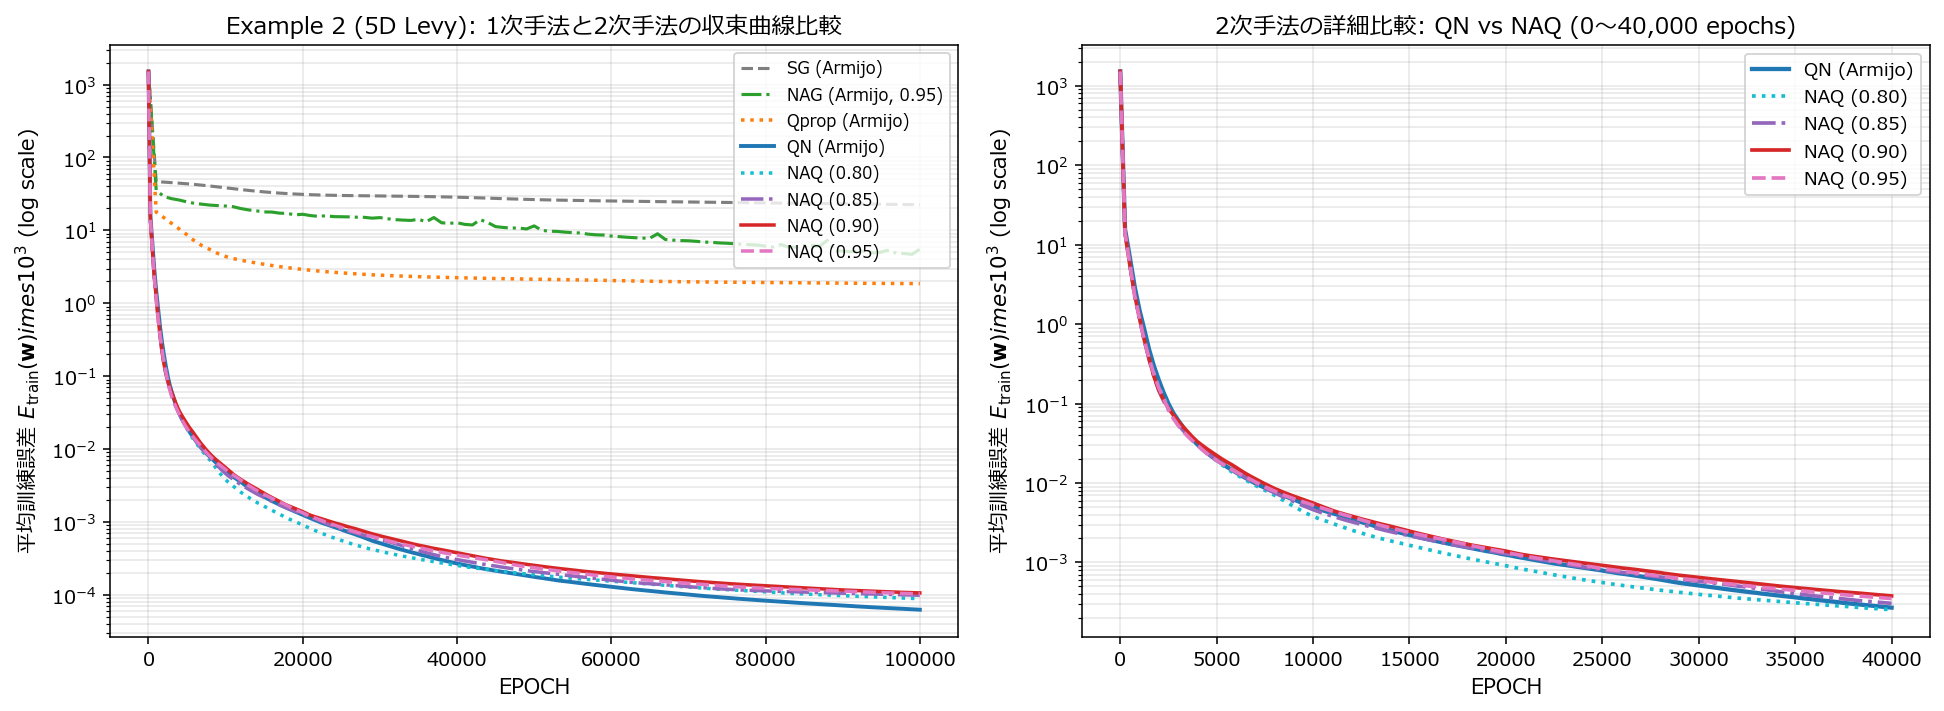

In [4]:
# 1) 収束曲線の比較 (1次手法 vs QN vs NAQ)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# 左: 全手法 (0〜100,000 epochs)
ep_1st = curves_armijo_1st["epochs"]
axes[0].plot(ep_1st, curves_armijo_1st["SG(Armijo)"] * 1e3, "--", color="#7f7f7f", lw=1.6, label="SG (Armijo)")
axes[0].plot(ep_1st, curves_armijo_1st["NAG(Armijo,0.95)"] * 1e3, "-.", color="#2ca02c", lw=1.6, label="NAG (Armijo, 0.95)")
axes[0].plot(ep_1st, curves_armijo_1st["Qprop(Armijo)"] * 1e3, ":", color="#ff7f0e", lw=1.8, label="Qprop (Armijo)")

qn_ep, qn_c = curves_2nd["QN"]
axes[0].plot(qn_ep, qn_c * 1e3, "-", color="#1f77b4", lw=2.0, label="QN (Armijo)")
for mu_s, col, ls in [("0.80", "#17becf", ":"), ("0.85", "#9467bd", "-."), ("0.90", "#d62728", "-"), ("0.95", "#e377c2", "--")]:
    nep, nc = curves_2nd[f"NAQ({mu_s})"]
    axes[0].plot(nep, nc * 1e3, linestyle=ls, color=col, lw=1.8, label=f"NAQ ({mu_s})")

axes[0].set_yscale("log")
axes[0].set_xlabel("EPOCH", fontsize=11)
axes[0].set_ylabel(r"平均訓練誤差 $E_{\mathrm{train}}(\mathbf{w}) 	imes 10^3$ (log scale)", fontsize=11)
axes[0].set_title("Example 2 (5D Levy): 1次手法と2次手法の収束曲線比較", fontsize=12)
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8.5, loc="upper right")

# 右: QN vs NAQ の詳細拡大比較 (0〜40,000 epochs)
mask_q = qn_ep <= 40000
axes[1].plot(qn_ep[mask_q], qn_c[mask_q] * 1e3, "-", color="#1f77b4", lw=2.2, label="QN (Armijo)")
for mu_s, col, ls in [("0.80", "#17becf", ":"), ("0.85", "#9467bd", "-."), ("0.90", "#d62728", "-"), ("0.95", "#e377c2", "--")]:
    nep, nc = curves_2nd[f"NAQ({mu_s})"]
    m = nep <= 40000
    axes[1].plot(nep[m], nc[m] * 1e3, linestyle=ls, color=col, lw=1.9, label=f"NAQ ({mu_s})")

axes[1].set_yscale("log")
axes[1].set_xlabel("EPOCH", fontsize=11)
axes[1].set_ylabel(r"平均訓練誤差 $E_{\mathrm{train}}(\mathbf{w}) 	imes 10^3$ (log scale)", fontsize=11)
axes[1].set_title("2次手法の詳細比較: QN vs NAQ (0〜40,000 epochs)", fontsize=12)
axes[1].grid(True, which="both", alpha=0.3)
axes[1].legend(fontsize=9.5)

plt.tight_layout()
plt.savefig("../report/img/ex003_convergence_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

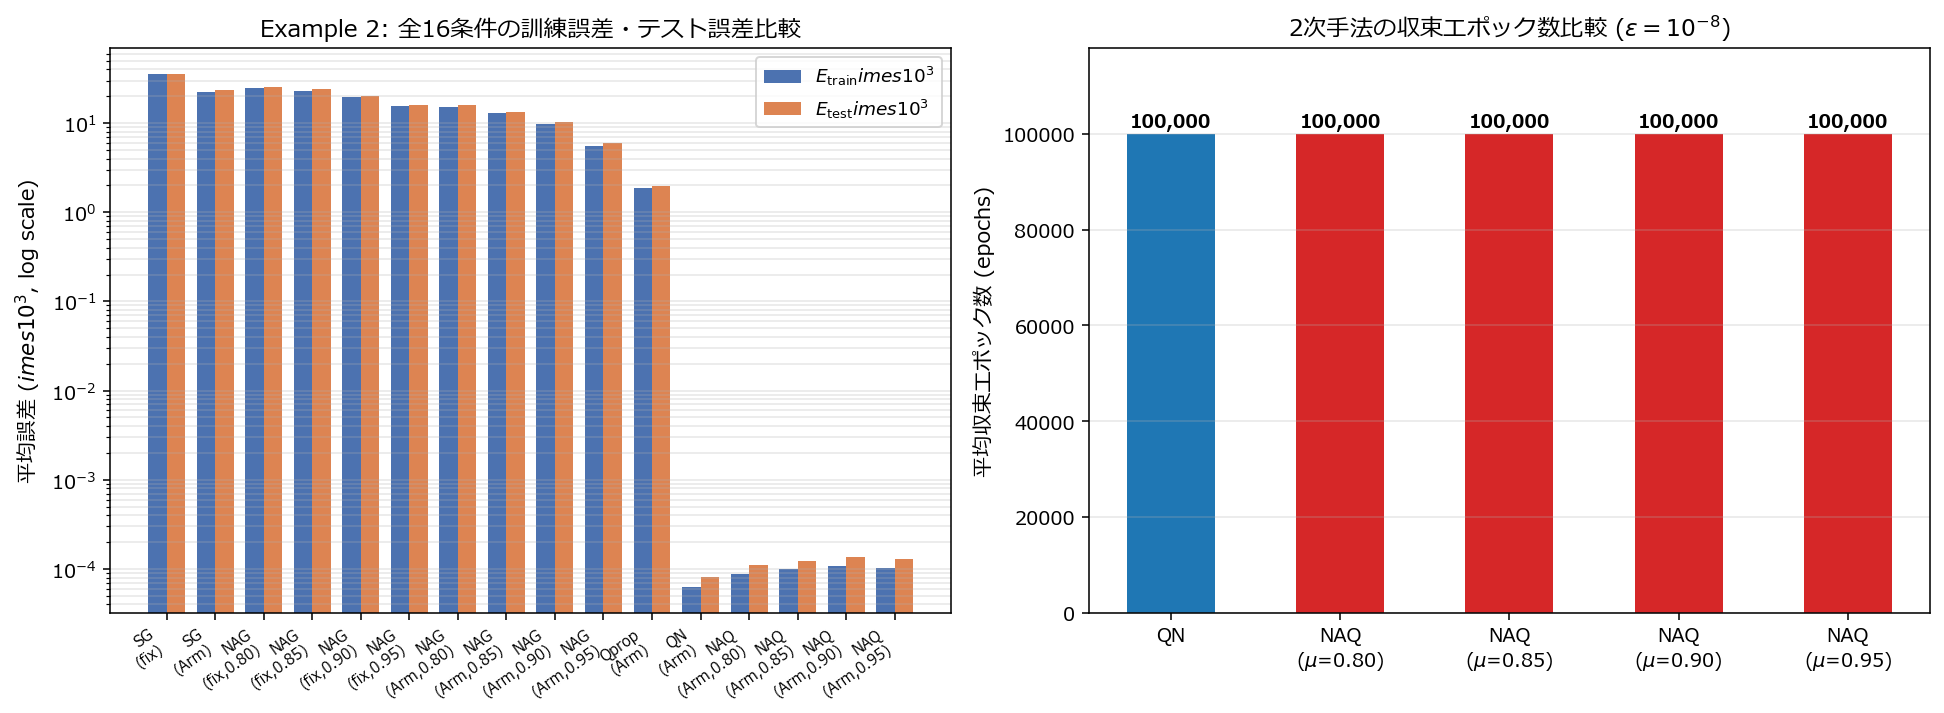

In [5]:
# 2) 全手法の訓練・テスト誤差と2次手法の収束エポック数比較
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

labels_all = [
    f"{r['algo']}\n({r['stepsize'][:3]}" + (f",{r['mu']})" if r["mu"] != "-" else ")")
    for r in ordered_results
]
x_idx = np.arange(len(ordered_results))
tr_vals = [r["train_ave"] for r in ordered_results]
te_vals = [r["test_ave"] for r in ordered_results]

axes[0].bar(x_idx - 0.19, tr_vals, 0.38, label=r"$E_{\mathrm{train}} 	imes 10^3$", color="#4c72b0")
axes[0].bar(x_idx + 0.19, te_vals, 0.38, label=r"$E_{\mathrm{test}} 	imes 10^3$", color="#dd8452")
axes[0].set_yscale("log")
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(labels_all, fontsize=7.5, rotation=35, ha="right")
axes[0].set_ylabel(r"平均誤差 ($	imes 10^3$, log scale)", fontsize=11)
axes[0].set_title("Example 2: 全16条件の訓練誤差・テスト誤差比較", fontsize=12)
axes[0].grid(True, which="both", axis="y", alpha=0.3)
axes[0].legend(fontsize=9.5)

# 右: QN vs NAQ の収束エポック数と訓練・テスト誤差
sec_names = ["QN"] + [f"NAQ\n($\mu$={r['mu']})" for r in res_2nd[1:]]
sec_epochs = [r["ave_epochs"] for r in res_2nd]
sec_cols = ["#1f77b4"] + ["#d62728"] * 4
bars = axes[1].bar(np.arange(len(res_2nd)), sec_epochs, width=0.52, color=sec_cols)
for b, ep in zip(bars, sec_epochs):
    axes[1].text(b.get_x() + b.get_width()/2, ep + 600, f"{int(round(ep)):,}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")

axes[1].set_xticks(np.arange(len(res_2nd)))
axes[1].set_xticklabels(sec_names, fontsize=10)
axes[1].set_ylabel("平均収束エポック数 (epochs)", fontsize=11)
axes[1].set_ylim(0, max(sec_epochs) * 1.18)
axes[1].set_title("2次手法の収束エポック数比較 ($\epsilon = 10^{-8}$)", fontsize=12)
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../report/img/ex003_algorithm_metrics.png", dpi=160, bbox_inches="tight")
plt.show()